# Day 09 | CNN: Learn Patterns in Images

**KGP Talkie | [kgptalkie.com](https://kgptalkie.com)**

We will build a **Convolutional Neural Network (CNN)**. It learns image patterns and uses them to choose a class: cat or dog.

Run the cells from top to bottom. Put the supplied `train.zip` in `day-09/data/`. The supplied horse photo is in `day-09/assets/`. Open this notebook from its `notebooks` folder. Training takes longer than the other cells.

The handout explains the ideas. Here we see the numbers, build the model, and try new photos.

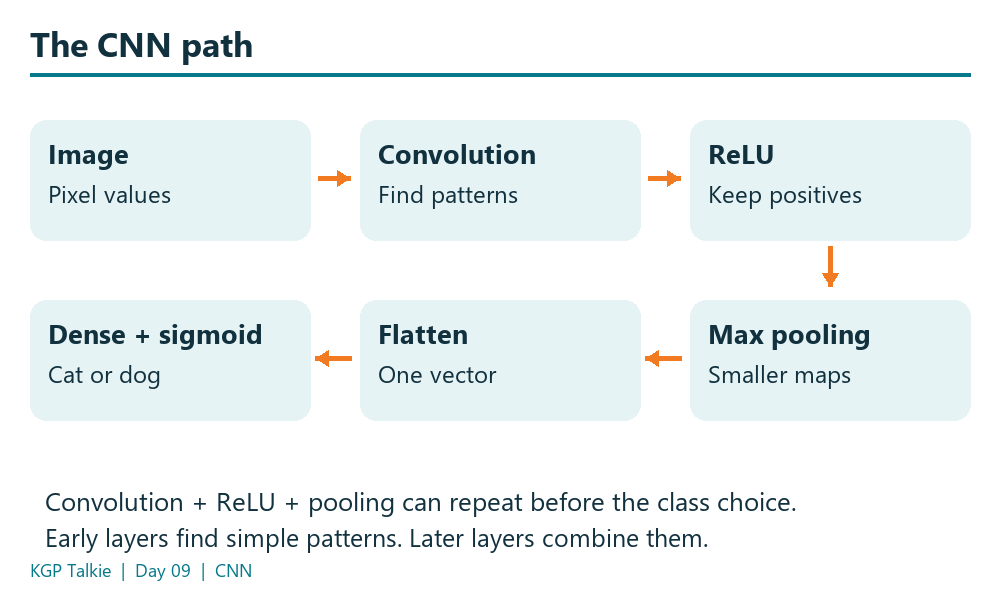

## 1. Import the tools

**TensorFlow** runs the calculations. **Keras** gives us ready-made layers. A **layer** changes its input and passes the result to the next layer.

In [1]:
import tensorflow as tf  # TensorFlow runs the CNN calculations.

In [2]:
from tensorflow import keras  # Keras lets us build and train the model.

In [3]:
from tensorflow.keras import layers  # Conv2D, pooling, and other layer types.

In [4]:
import numpy as np  # NumPy stores small grids and combines test outputs.

In [5]:
import matplotlib.pyplot as plt  # Matplotlib displays photos and charts.

In [6]:
from pathlib import Path  # Path joins folder and file names.

In [7]:
import zipfile  # zipfile opens our compressed image archive.

In [8]:
import shutil  # shutil copies photos into separate learning groups.

In [9]:
keras.utils.set_random_seed(42)  # Fix the starting random choices; 42 is just a chosen seed.

## 2. See one convolution calculation

A **filter**, also called a **kernel**, is a small grid of weights. We multiply matching cells and add the products. This fixed edge filter is a demo. Our trained CNN will learn its own filter values.

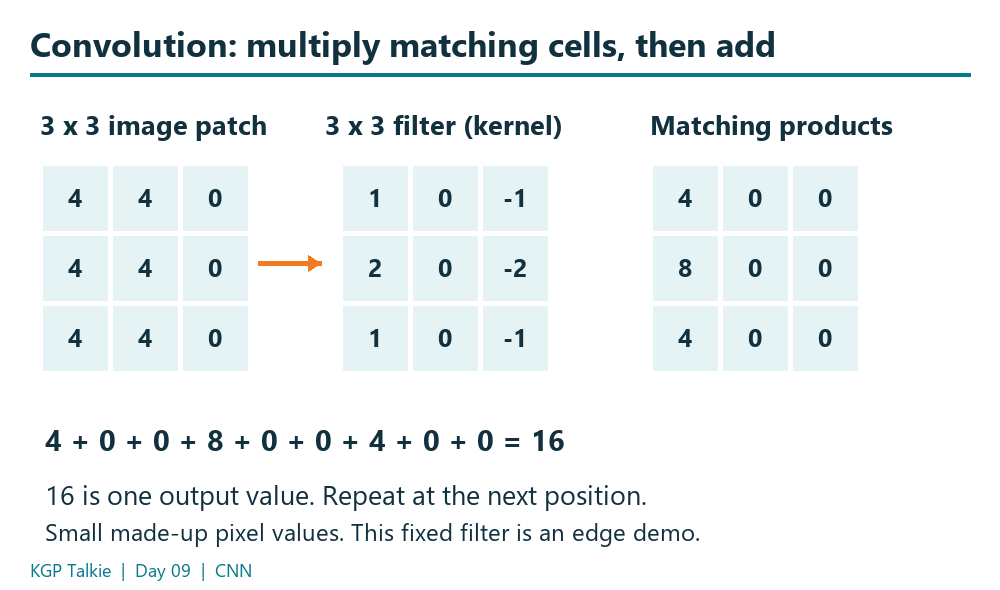

In [10]:
patch = np.array([[4, 4, 0], [4, 4, 0], [4, 4, 0]])  # Small made-up pixel values.

In [11]:
kernel = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]])  # A vertical edge filter.

In [12]:
patch * kernel  # * multiplies each pixel by its matching filter weight.

array([[4, 0, 0],
       [8, 0, 0],
       [4, 0, 0]])

In [13]:
(patch * kernel).sum()  # sum() adds the nine products: one output value, 16.

np.int64(16)

Move this filter across the image. Each position gives one value in a **feature map**, a grid showing where the filter responds.

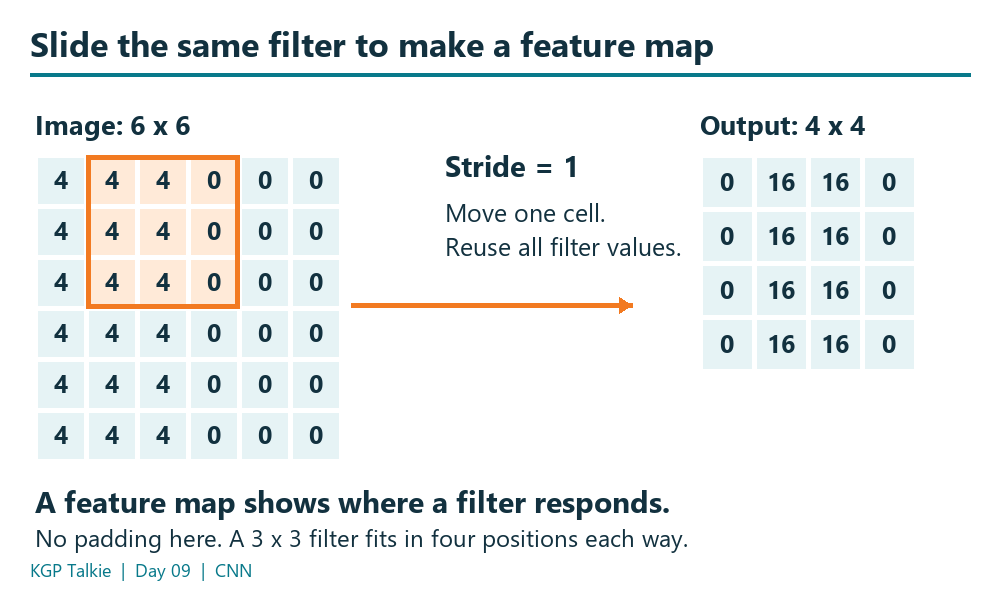

## 3. Set the project paths

A path tells Python where to find a file. `..` means the parent folder of this notebook. We keep raw photos, split photos, and saved models in different folders.

In [14]:
zip_path = Path("../data/train.zip")  # The supplied archive, one folder above this notebook.

In [15]:
raw_folder = Path("../data/source")  # The archive will create a train folder here.

In [16]:
original_dir = raw_folder / "train"  # / joins names: source/train.

In [17]:
split_folder = Path("../data/subsets")  # Our train, validation, and test groups.

In [18]:
model_path = Path("../models/day-09-cats-dogs.keras")  # The best saved model.

In [19]:
horse_path = Path("../assets/inputimage.png")  # The supplied photo contains a horse.

In [20]:
model_path.parent.mkdir(parents=True, exist_ok=True)  # Make the model folder; keep it if it exists.

In [21]:
assert zip_path.is_file(), "Put train.zip in day-09/data before running this notebook."

## 4. Extract the supplied photos

The archive contains `train/cat.0.jpg`, `train/dog.0.jpg`, and many more photos. The `if` checks whether we already extracted it. This avoids doing the same work on every run. Use this cell with the supplied archive.

In [22]:
if not original_dir.exists():  # Extract once; later runs use the same source folder.
    with zipfile.ZipFile(zip_path) as archive:  # Open the supplied ZIP; close it when done.
        archive.extractall(raw_folder)  # Unpack the images into source/train.
print("Cat photos:", len(list(original_dir.glob("cat.*.jpg"))))
print("Dog photos:", len(list(original_dir.glob("dog.*.jpg"))))

Cat photos: 12500
Dog photos: 12500


## 5. Keep learning and testing separate

**Training data** changes the weights. **Validation data** helps choose the saved model. **Test data** gives the final score after training. The number ranges below do not overlap.

We use the same subset sizes as the supplied cats-and-dogs notebook. Each group has equal numbers of cats and dogs.

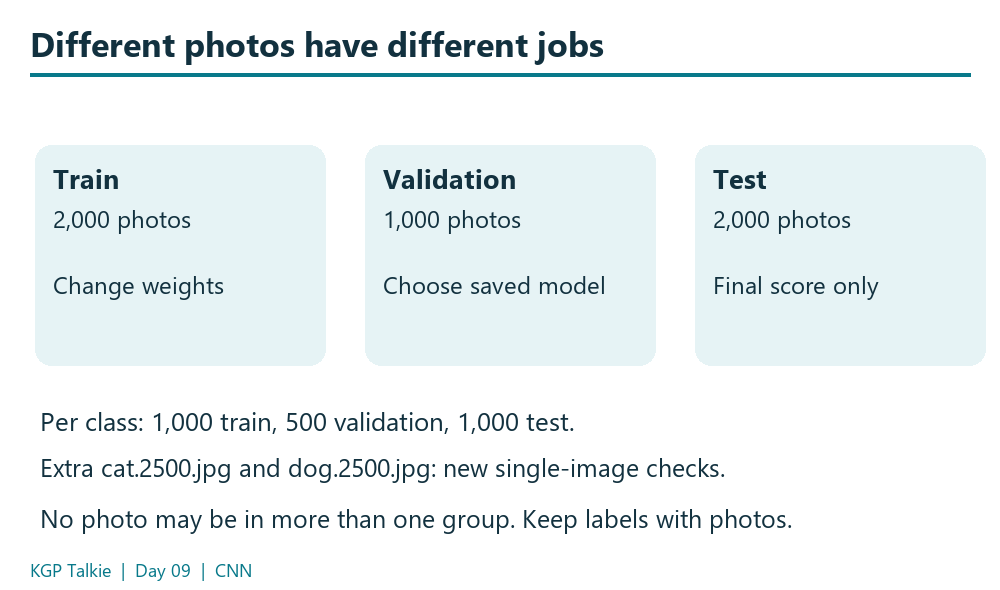

### A function to copy one group

`make_subset` is a **function**, a named set of steps. Its **parameters** are the group name and the start and end numbers. `range(start, end)` includes the start and stops before the end. For example, `range(0, 3)` gives 0, 1, 2.

The outer loop visits cat and dog. The inner loop visits each photo number. The filename joins them: cat + 12 becomes `cat.12.jpg`.

In [23]:
def make_subset(subset_name, start_index, end_index):
    for category in ("cat", "dog"):  # Give both classes the same number of photos.
        destination = split_folder / subset_name / category  # For example: subsets/train/cat.
        destination.mkdir(parents=True, exist_ok=True)  # Create folders; allow a repeat run.
        for index in range(start_index, end_index):  # The end number is not included.
            filename = f"{category}.{index}.jpg"  # f inserts values into the filename.
            shutil.copyfile(original_dir / filename, destination / filename)  # Copy, keep the original.

In [24]:
make_subset("train", 0, 1000)  # cat/dog numbers 0 to 999: 2,000 training photos.

In [25]:
make_subset("validation", 1000, 1500)  # Numbers 1000 to 1499: 1,000 validation photos.

In [26]:
make_subset("test", 1500, 2500)  # Numbers 1500 to 2499: 2,000 test photos.

In [27]:
for group in ("train", "validation", "test"):
    counts = [len(list((split_folder / group / category).glob("*.jpg"))) for category in ("cat", "dog")]
    print(group, "| cats:", counts[0], "| dogs:", counts[1])  # Check the copied class counts.

train | cats: 1000 | dogs: 1000
validation | cats: 500 | dogs: 500
test | cats: 1000 | dogs: 1000


## 6. Read photos in batches

A **batch** is a small group of photos processed together. We use 32, as in the resource. The last batch may contain fewer photos.

`image_dataset_from_directory` reads each class folder and gives us images with their labels. We set the class order, so **cat = 0** and **dog = 1** everywhere. `label_mode="binary"` gives one 0 or 1 per photo.

Every image becomes 180 pixels high and 180 wide. RGB means 3 color channels. A **channel** is one color part: red, green, or blue. A **tensor** is an array of numbers; TensorFlow stores image batches as tensors. The model expects this same size for training and new photos. Resizing may change a photo's shape; it keeps the input size fixed.

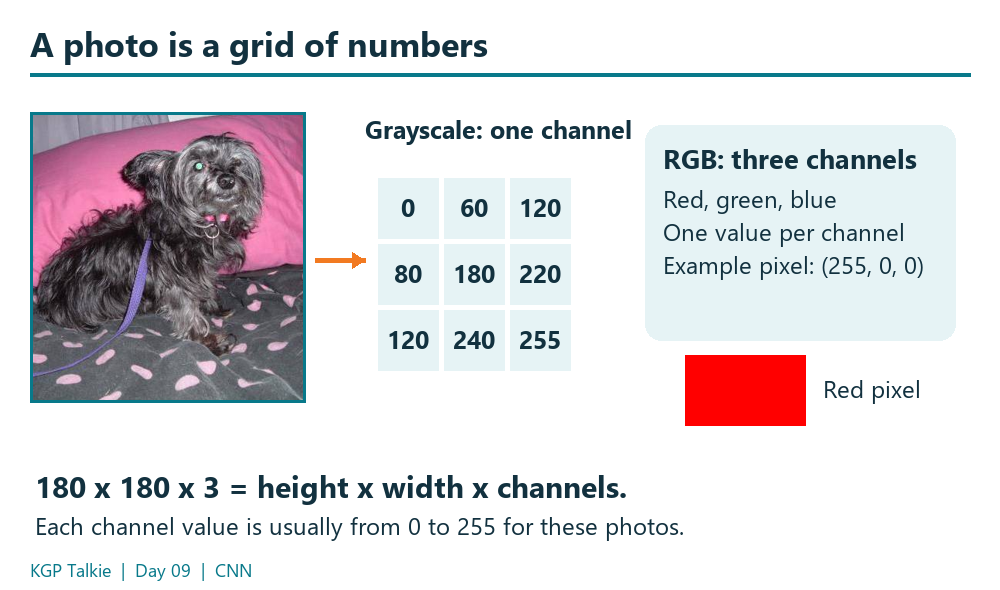

In [28]:
class_names = ["cat", "dog"]  # Position 0 is cat; position 1 is dog.

In [29]:
image_size = (180, 180)  # (height, width), matching the supplied cats-and-dogs model.

In [30]:
batch_size = 32  # Process up to 32 photos before one weight update.

In [31]:
train_dataset = keras.utils.image_dataset_from_directory(
    split_folder / "train", class_names=class_names, label_mode="binary",
    image_size=image_size, batch_size=batch_size, interpolation="bilinear",
    shuffle=True, seed=42)  # Mix training order; bilinear blends nearby pixels during resizing.

Found 2000 files belonging to 2 classes.


In [32]:
validation_dataset = keras.utils.image_dataset_from_directory(
    split_folder / "validation", class_names=class_names, label_mode="binary",
    image_size=image_size, batch_size=batch_size, interpolation="bilinear",
    shuffle=False)  # A fixed order makes the validation results easy to check.

Found 1000 files belonging to 2 classes.


In [33]:
test_dataset = keras.utils.image_dataset_from_directory(
    split_folder / "test", class_names=class_names, label_mode="binary",
    image_size=image_size, batch_size=batch_size, interpolation="bilinear",
    shuffle=False)  # Keep predictions and true labels in the same order.

Found 2000 files belonging to 2 classes.


In [34]:
images, labels = next(iter(train_dataset))  # Read the first batch: inputs and known answers.

In [35]:
images.shape  # (batch size, height, width, channels): normally (32, 180, 180, 3).

TensorShape([32, 180, 180, 3])

In [36]:
labels[:6].numpy().reshape(-1)  # Show the first six labels as one row; -1 finds its length.

array([1., 1., 1., 0., 0., 0.], dtype=float32)

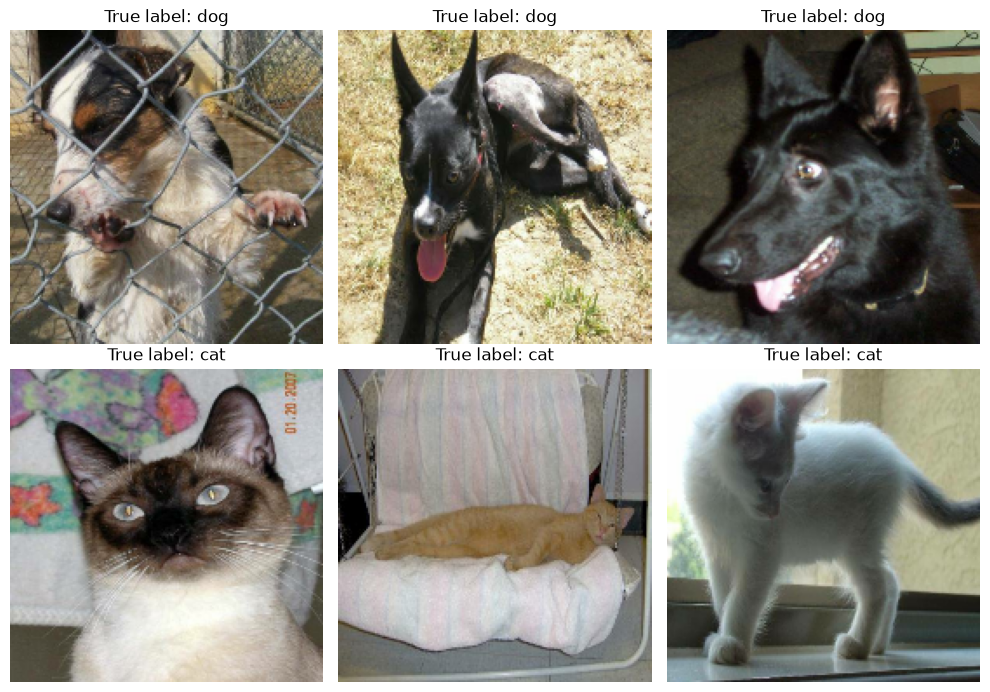

In [37]:
fig, axes = plt.subplots(2, 3, figsize=(10, 7))  # Two rows, three photo spaces.
for index, ax in enumerate(axes.flat):  # Visit all six Axes in order.
    ax.imshow(images[index].numpy().astype("uint8"))  # uint8 shows pixels in the 0 to 255 range.
    label = int(labels[index, 0])  # One known class number for this photo.
    ax.set_title(f"True label: {class_names[label]}")
    ax.axis("off")  # Hide number axes around photos.
plt.tight_layout()
plt.show()

## 7. Build the CNN, one layer at a time

We follow the resource model: five convolution layers, four pooling layers, Flatten, and one sigmoid output.

The **Functional API** connects layers by passing one layer's result to the next. In `x = layer(x)`, the right-hand `x` is the old input. The left-hand `x` becomes the new output.

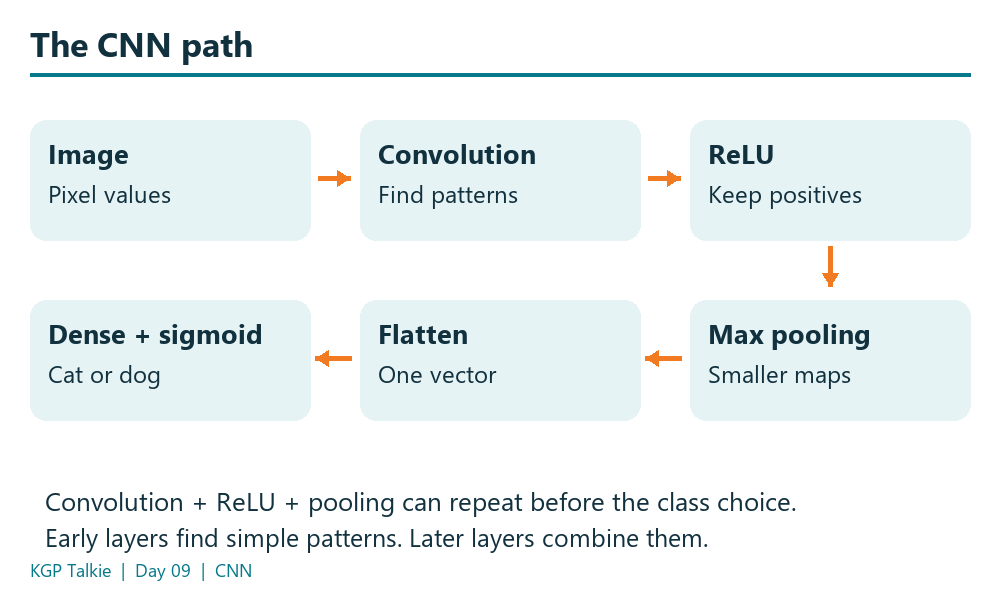

### Input and rescaling

`Input` describes one photo's shape. The batch dimension is added by Keras. `Rescaling` divides pixels by 255 inside the model, so the same change happens during training and prediction.

In [38]:
inputs = keras.Input(shape=(180, 180, 3), name="image")  # 180 rows, 180 columns, 3 RGB channels.

In [39]:
x = layers.Rescaling(1.0 / 255, name="rescale")(inputs)  # Turn 0 to 255 into 0 to 1, exactly once.

### First convolution and pooling

`Conv2D` uses a filter over two image directions: height and width. `filters=32` means 32 learned filters and 32 output maps. `kernel_size=3` means each filter covers a 3 x 3 patch.

We state the resource defaults: `strides=1` moves one pixel; `padding="valid"` adds no border. `activation="relu"` changes negative results to zero. The output becomes 178 x 178 x 32.

`MaxPooling2D(pool_size=2)` keeps the largest value in each 2 x 2 patch. Its default stride is 2. This halves 178 to 89 and keeps 32 channels.

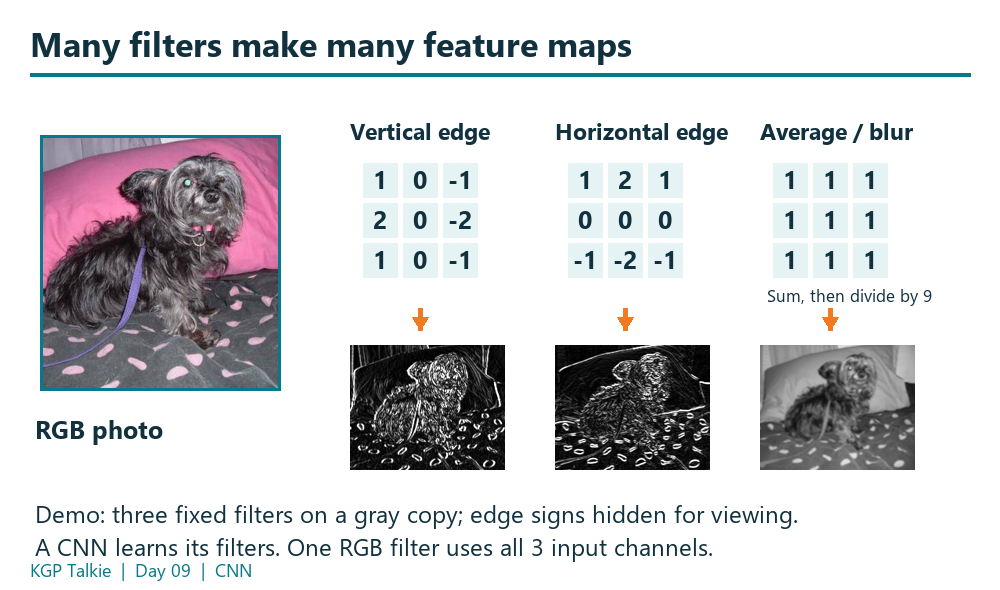

In [40]:
x = layers.Conv2D(filters=32, kernel_size=3, strides=1, padding="valid", activation="relu", name="conv_1")(x)

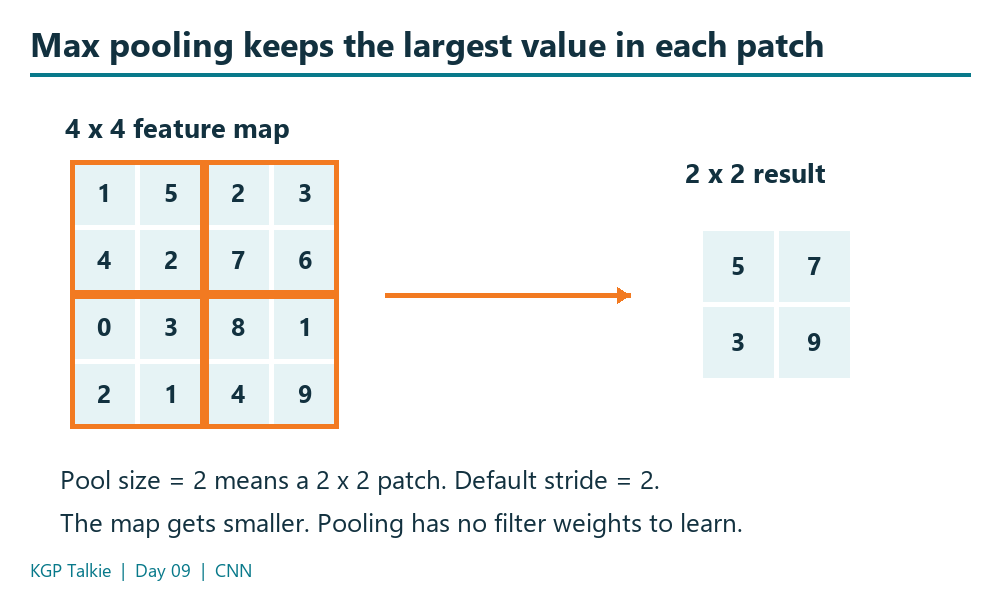

In [41]:
x = layers.MaxPooling2D(pool_size=2, name="pool_1")(x)  # Smaller maps mean fewer later calculations.

### Repeat to combine patterns

Later layers use the earlier maps as input. Small edges can become more complex patterns. More filters give room for more patterns as the maps get smaller. These sizes follow your resource; they are choices, not a rule for every CNN.

In [42]:
x = layers.Conv2D(64, 3, activation="relu", name="conv_2")(x)  # 64 maps, each 87 x 87; default stride 1, no border.

In [43]:
x = layers.MaxPooling2D(2, name="pool_2")(x)  # 87 x 87 becomes 43 x 43; incomplete edge patches are left out.

In [44]:
x = layers.Conv2D(128, 3, activation="relu", name="conv_3")(x)  # 128 maps, each 41 x 41.

In [45]:
x = layers.MaxPooling2D(2, name="pool_3")(x)  # Each map becomes 20 x 20.

In [46]:
x = layers.Conv2D(256, 3, activation="relu", name="conv_4")(x)  # 256 maps, each 18 x 18.

In [47]:
x = layers.MaxPooling2D(2, name="pool_4")(x)  # Each map becomes 9 x 9.

In [48]:
x = layers.Conv2D(256, 3, activation="relu", name="conv_5")(x)  # 256 maps, each 7 x 7; no pooling after this one.

### Flatten and the output

**Flatten** turns the maps into one **vector**, a one-dimensional row of numbers. It keeps all values: 7 x 7 x 256 = 12,544 numbers. **Dense** uses a weighted sum and a bias. **Sigmoid** turns the final score into a value from 0 to 1, used as the estimated dog probability. Cat probability is 1 minus that value.

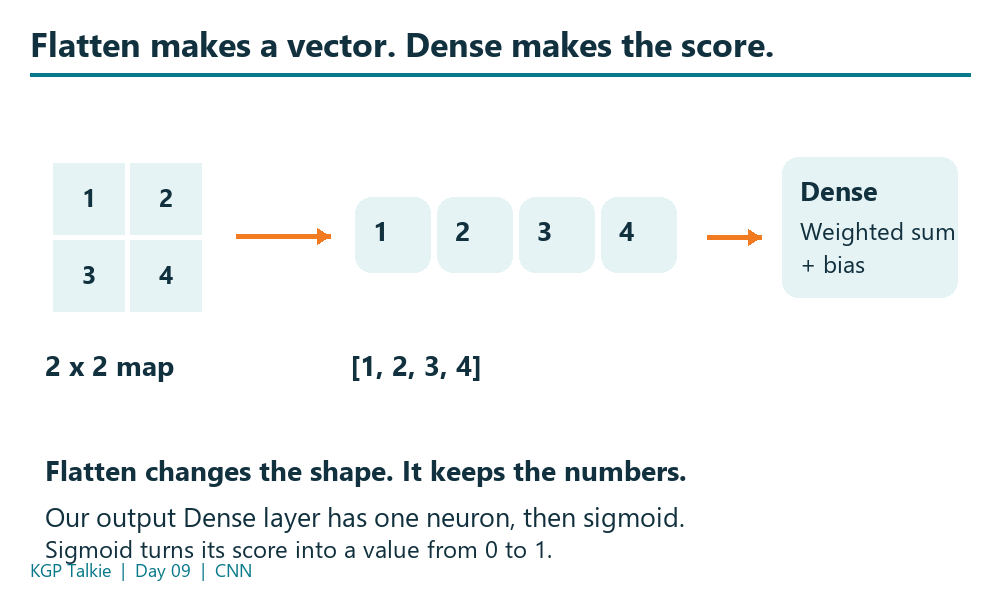

In [49]:
x = layers.Flatten(name="flatten")(x)  # One vector of 12,544 values for each photo.

In [50]:
outputs = layers.Dense(1, activation="sigmoid", name="dog_probability")(x)  # One output because there are two classes.

In [51]:
model = keras.Model(inputs=inputs, outputs=outputs)  # Connect the complete input-to-output path.

In [52]:
model.summary()  # Output Shape shows size; Param # counts learned weights and biases.

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_4 (Conv2D)                 │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_4 (MaxPooling2D)           │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_5 (Conv2D)                 │ (None, 7, 7, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dog_probability (Dense)         │ (None, 1)              │        12,545 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 991,041 (3.78 MB)

 Trainable params: 991,041 (3.78 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Choose how the model learns

**Loss** is a penalty for a wrong prediction. `binary_crossentropy` fits two-class probability predictions. It gives a large penalty for being sure of a wrong answer.

An **optimizer** changes the weights using change signals called **gradients**. We use `rmsprop`, as in the resource. **Accuracy** counts correct class choices. Loss guides learning; accuracy helps us read the result.

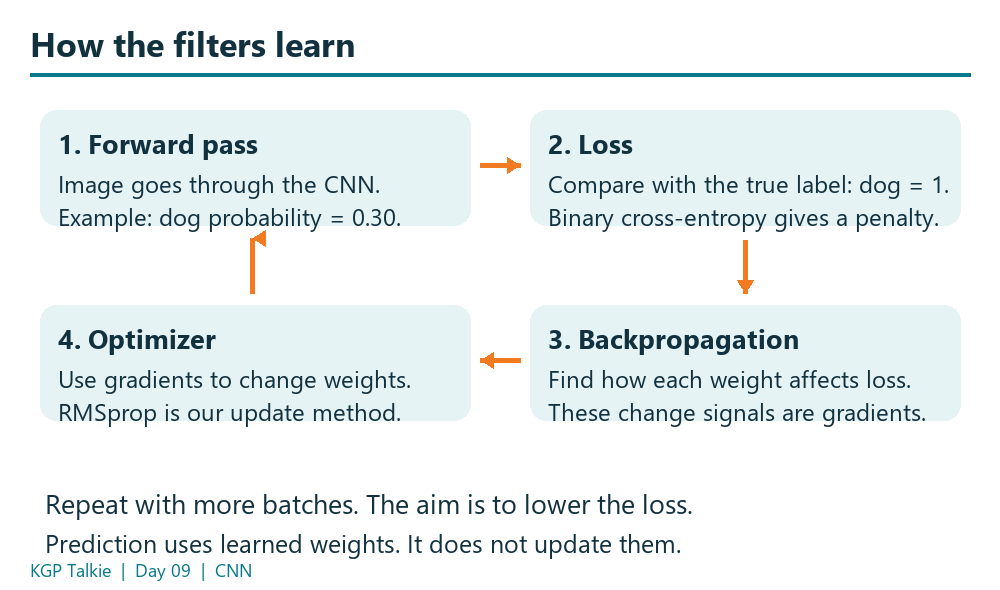

In [53]:
model.compile(loss="binary_crossentropy", optimizer="rmsprop", metrics=["accuracy"])  # Two classes, RMSprop updates, correct-class score.

## 9. Train and save the best model

An **epoch** is one pass through all training photos. We use 10 epochs to give the small training set more passes through the model. This is a starting choice, so errors are expected. More training is not always better: the model may learn training photos too closely.

A **callback** runs an extra task during training. `ModelCheckpoint` saves the model whenever validation loss is lower than before. `save_best_only=True` keeps that version. We do not use test photos to choose it.

In [54]:
checkpoint = keras.callbacks.ModelCheckpoint(filepath=str(model_path), monitor="val_loss", save_best_only=True)  # Lower validation loss wins.

In [55]:
history = model.fit(train_dataset, epochs=10, validation_data=validation_dataset, callbacks=[checkpoint], shuffle=False, verbose=2)  # Print one summary per epoch; the training dataset already mixes its order.

Epoch 1/10


63/63 - 29s - 457ms/step - accuracy: 0.4905 - loss: 0.7191 - val_accuracy: 0.5000 - val_loss: 0.6926


Epoch 2/10


63/63 - 41s - 655ms/step - accuracy: 0.5355 - loss: 0.6920 - val_accuracy: 0.5000 - val_loss: 0.7245


Epoch 3/10


...

63/63 - 26s - 420ms/step - accuracy: 0.7230 - loss: 0.5276 - val_accuracy: 0.6850 - val_loss: 0.5825


Epoch 9/10


63/63 - 28s - 437ms/step - accuracy: 0.7490 - loss: 0.5059 - val_accuracy: 0.6930 - val_loss: 0.6197


Epoch 10/10


63/63 - 28s - 452ms/step - accuracy: 0.7850 - loss: 0.4497 - val_accuracy: 0.7120 - val_loss: 0.6059


## 10. Read the learning curves

The training line shows the photos used to change weights. The validation line shows other photos. If training keeps improving but validation loss rises, this can be **overfitting**, learning the training examples too closely.

In [56]:
epochs = range(1, len(history.history["loss"]) + 1)  # Label epochs starting at 1, not 0.

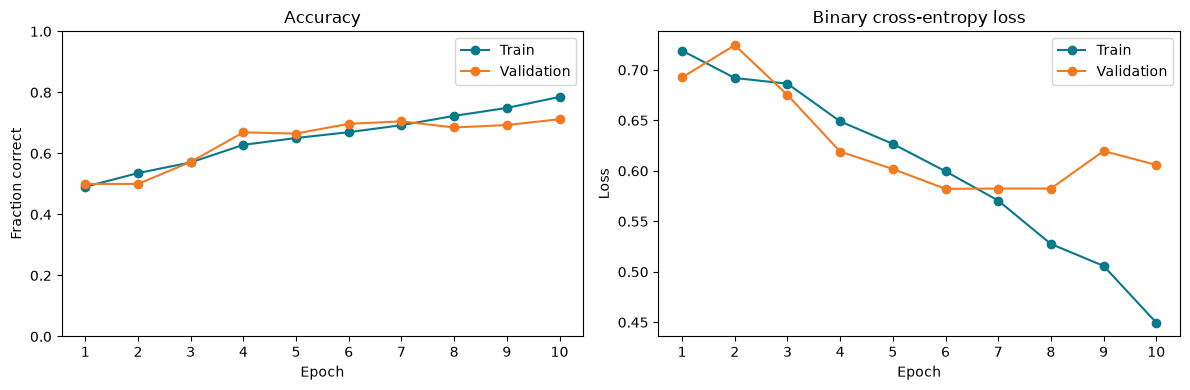

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history.history["accuracy"], "o-", color="#08798a", label="Train")
axes[0].plot(epochs, history.history["val_accuracy"], "o-", color="#f27a21", label="Validation")
axes[0].set(title="Accuracy", xlabel="Epoch", ylabel="Fraction correct", ylim=(0, 1))
axes[1].plot(epochs, history.history["loss"], "o-", color="#08798a", label="Train")
axes[1].plot(epochs, history.history["val_loss"], "o-", color="#f27a21", label="Validation")
axes[1].set(title="Binary cross-entropy loss", xlabel="Epoch", ylabel="Loss")
for ax in axes:
    ax.legend()  # Say which line is which.
    ax.set_xticks(list(epochs))  # Use whole epoch numbers.
plt.tight_layout()
plt.show()

## 11. Evaluate on the separate test photos

Load the best saved model. This may differ from the last epoch. `evaluate` compares its predictions with the known test labels. Equal class counts make accuracy useful here. Accuracy alone does not show which class causes the mistakes.

In [58]:
test_model = keras.models.load_model(model_path)  # Use the model picked by validation loss.

In [59]:
test_loss, test_accuracy = test_model.evaluate(test_dataset, verbose=0)  # 2,000 unseen test photos; no weight updates.

In [60]:
print(f"Test accuracy: {test_accuracy:.1%} | Test loss: {test_loss:.3f}")  # 0.70 would mean 70% correct.

Test accuracy: 68.6% | Test loss: 0.604


### Check the two types of mistakes

A **confusion matrix** counts true classes against predicted classes. Its diagonal counts correct answers. We kept `shuffle=False` for the test data, so its predictions and labels match in order.

In [61]:
dog_probabilities = test_model.predict(test_dataset, verbose=0).reshape(-1)  # One long list: one dog probability per test photo.

In [62]:
predicted_labels = (dog_probabilities >= 0.5).astype("int32")  # True becomes 1 (dog); False becomes 0 (cat).

In [63]:
label_batches = []  # Collect each batch of known labels.
for _, batch_labels in test_dataset:  # _ means we do not need the images for this step.
    label_batches.append(batch_labels.numpy().reshape(-1))  # Change each label column into a one-dimensional array.

In [64]:
true_labels = np.concatenate(label_batches).astype("int32")  # Join batch arrays in order; use whole-number labels.

In [65]:
matrix = tf.math.confusion_matrix(true_labels, predicted_labels, num_classes=2).numpy()  # Rows: true; columns: predicted.

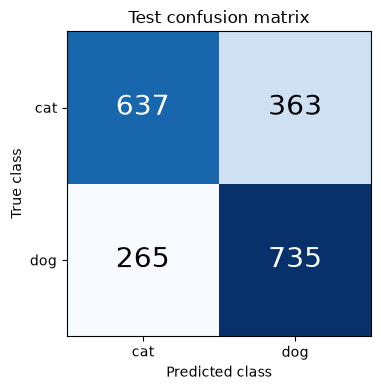

In [66]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(matrix, cmap="Blues")
for row in range(2):
    for column in range(2):
        ax.text(column, row, matrix[row, column], ha="center", va="center", fontsize=20, color="white" if matrix[row, column] > matrix.max() / 2 else "black")  # White text on dark cells.
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=class_names, yticklabels=class_names,
       xlabel="Predicted class", ylabel="True class", title="Test confusion matrix")
plt.tight_layout()
plt.show()

In [67]:
print("Correct:", np.trace(matrix), "| Wrong:", matrix.sum() - np.trace(matrix))  # trace() adds the diagonal counts.

Correct: 1372 | Wrong: 628


### Look at mistakes too

`!=` means "not equal". It compares each known label with the prediction. `flatnonzero` finds the positions where this comparison is True. We display the first four mistakes, without choosing which photos look best.

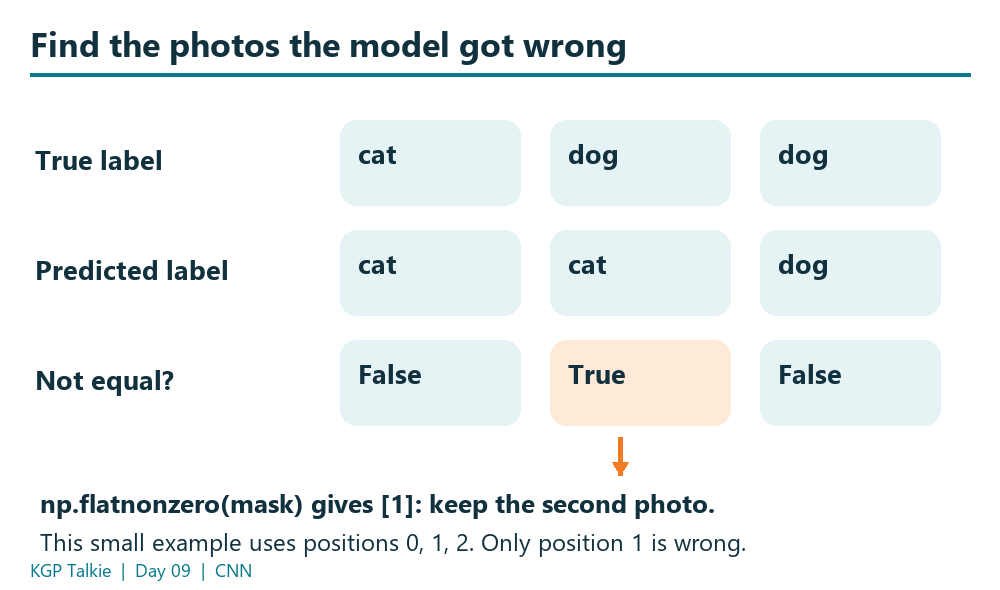

In [68]:
test_paths = sorted((split_folder / "test").glob("*/*.jpg"))  # Same sorted class and filename order as the test dataset.

In [69]:
wrong_positions = np.flatnonzero(true_labels != predicted_labels)  # Find positions of wrong class choices.

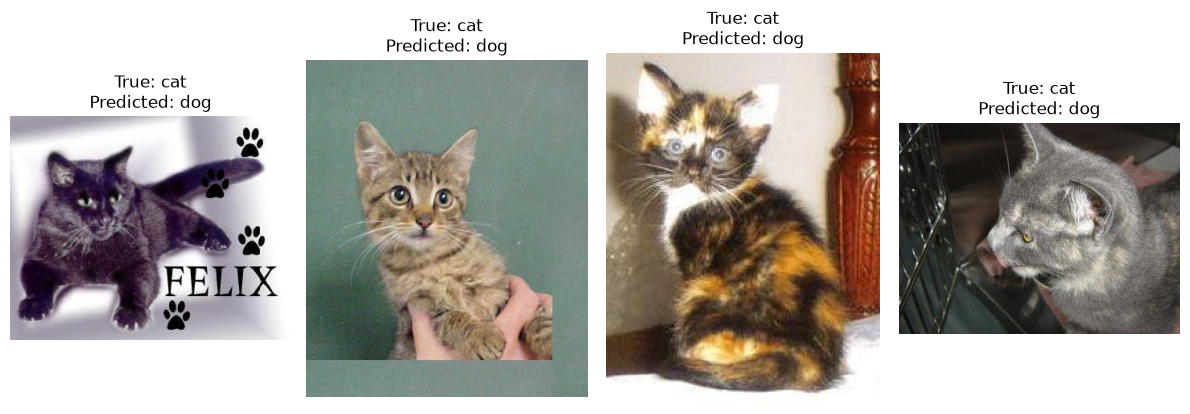

In [70]:
fig, axes = plt.subplots(1, 4, figsize=(12, 4))
for ax, position in zip(axes, wrong_positions[:4]):  # Up to four errors; keep their test order.
    ax.imshow(keras.utils.load_img(test_paths[position]))  # View the source photo.
    ax.set_title(f"True: {class_names[true_labels[position]]}\nPredicted: {class_names[predicted_labels[position]]}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 12. Try a different input, one photo at a time

These next two photos are outside the train, validation, and test ranges. We know their labels from the source filenames.

`load_img` resizes a photo and reads RGB colors. `img_to_array` changes it to numbers. `expand_dims(..., axis=0)` adds the batch dimension: the model expects a batch even when it contains only one photo.

We use **bilinear resizing** for both datasets and single photos. The model already contains rescaling, so we must not divide by 255 a second time.

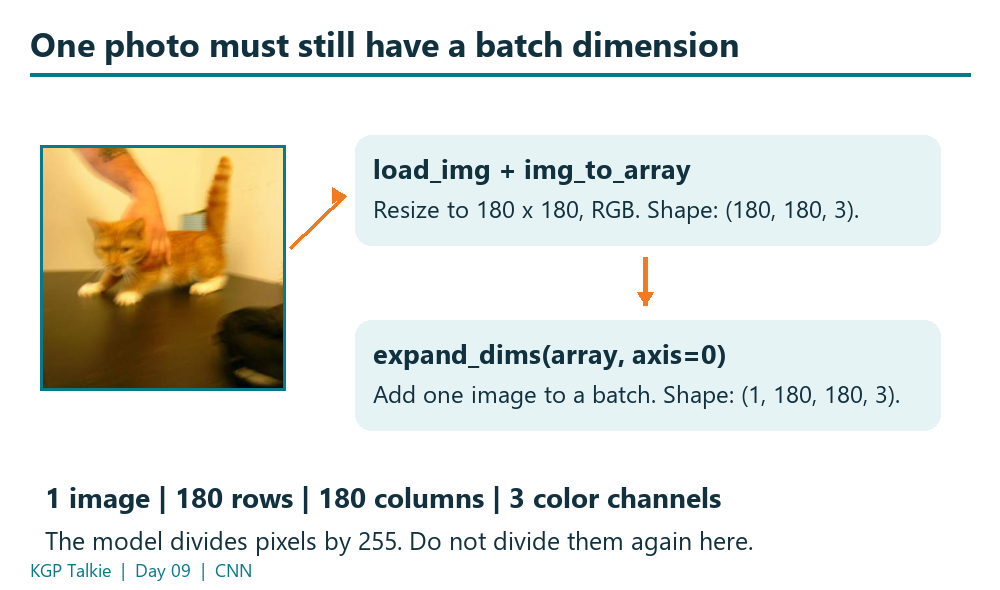

### First inspect one input step by step

In [71]:
new_cat_path = original_dir / "cat.2500.jpg"  # This index was not copied into any learning or test group.

In [72]:
new_dog_path = original_dir / "dog.2500.jpg"  # A second different input, also outside all three groups.

In [73]:
image = keras.utils.load_img(new_cat_path, color_mode="rgb", target_size=image_size, interpolation="bilinear")  # Same color and resize rules as training.

In [74]:
image_array = keras.utils.img_to_array(image)  # Convert the photo to a float array of pixel values.

In [75]:
image_array.shape  # (180, 180, 3): this is one photo, not a batch yet.

(180, 180, 3)

In [76]:
image_batch = tf.expand_dims(image_array, axis=0)  # Put a batch dimension in front; axis=0 means the start.

In [77]:
image_batch.shape  # (1, 180, 180, 3): a batch with one photo.

TensorShape([1, 180, 180, 3])

In [78]:
dog_probability = float(test_model.predict(image_batch, verbose=0)[0, 0])  # [0, 0] selects the first photo and its single output.

In [79]:
print(f"Estimated dog probability: {dog_probability:.3f}")  # A model estimate, not a guarantee.

Estimated dog probability: 0.567


### Reuse those steps for both photos

The function below does the same steps, then displays the photo and result. `expected` is the known answer for our check; it is not given to the model. We use the same 0.5 threshold as the test metrics.

In [80]:
def predict_photo(path, expected):
    image = keras.utils.load_img(path, color_mode="rgb", target_size=image_size, interpolation="bilinear")
    array = keras.utils.img_to_array(image)  # Keep 0 to 255; the saved model rescales it.
    batch = tf.expand_dims(array, axis=0)  # One photo becomes a one-photo batch.
    probability = float(test_model.predict(batch, verbose=0)[0, 0])  # Estimated dog probability.
    predicted = "dog" if probability >= 0.5 else "cat"  # The two-class decision rule.
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.title(f"Known: {expected} | Predicted: {predicted}\nEstimated dog probability: {probability:.3f}")
    plt.axis("off")
    plt.show()
    return predicted, probability  # Return the result so we can compare the two checks.

In [81]:
for path in (new_cat_path, new_dog_path):
    for group in ("train", "validation", "test"):
        assert not list((split_folder / group).rglob(path.name)), f"{path.name} must be outside {group}."
print("Both new photos are outside train, validation, and test.")

Both new photos are outside train, validation, and test.


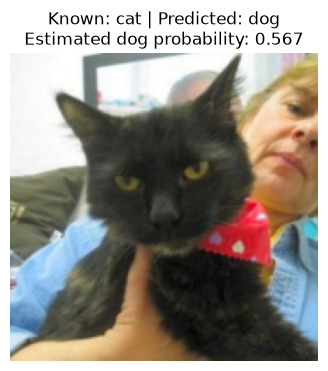

In [82]:
cat_check = predict_photo(new_cat_path, expected="cat")  # First fresh input. Check the shown answer, even if wrong.

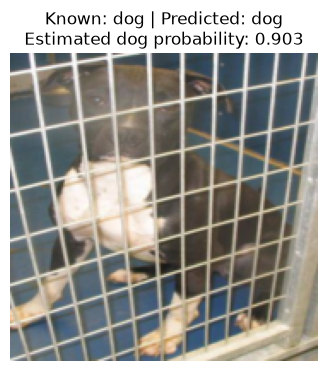

In [83]:
dog_check = predict_photo(new_dog_path, expected="dog")  # Second fresh input. Same saved model and input preparation.

In [84]:
print("Fresh-photo checks correct:", int(cat_check[0] == "cat") + int(dog_check[0] == "dog"), "out of 2")  # Two examples are not a full accuracy score.

Fresh-photo checks correct: 1 out of 2


## 13. See feature maps from our trained model

This smaller model ends at `conv_1`. It shares the trained weights and does not train again. We show six of its 32 maps for the new cat photo. Bright values mean a stronger response after ReLU.

These are learned maps. We should not assume that a map means "ear" or "eye" without checking it.

In [85]:
feature_model = keras.Model(inputs=test_model.input, outputs=test_model.get_layer("conv_1").output)  # Stop after the first convolution and ReLU.

In [86]:
feature_maps = feature_model.predict(image_batch, verbose=0)  # The batch still contains the new cat photo.

In [87]:
feature_maps.shape  # (1, 178, 178, 32): one image and 32 feature maps.

(1, 178, 178, 32)

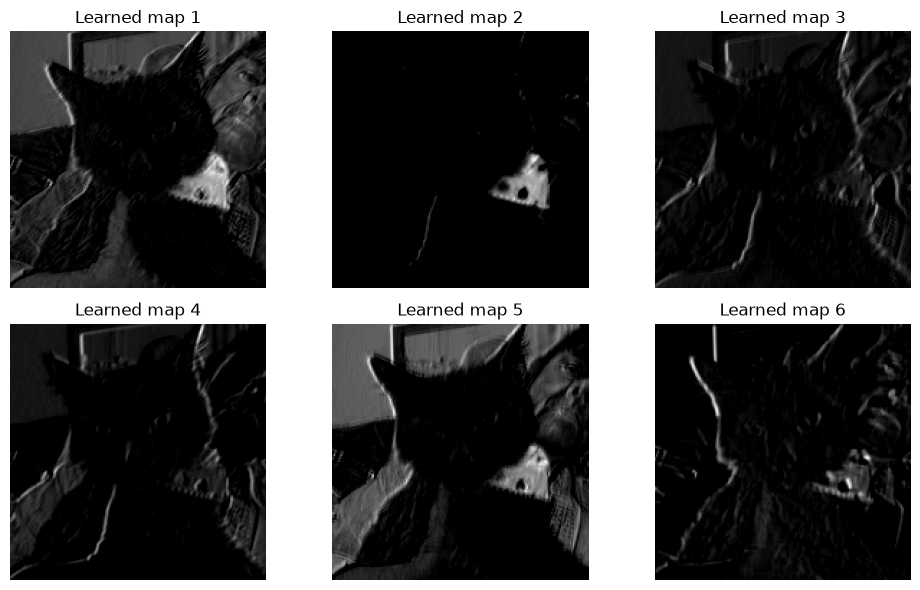

In [88]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for index, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[0, :, :, index], cmap="gray")  # First image, every row and column, one map.
    ax.set_title(f"Learned map {index + 1}")  # Each map uses its own display scale.
    ax.axis("off")
plt.tight_layout()
plt.show()

## 14. Try the supplied horse photo

This photo is neither cat nor dog. Our output has only those two classes, so it will still choose one. The chosen label is **not a valid animal name for this photo**. A high probability does not solve this problem.

To identify horses too, we need a horse class and suitable training examples. Do not treat a low probability or a high probability alone as an "unknown animal" detector.

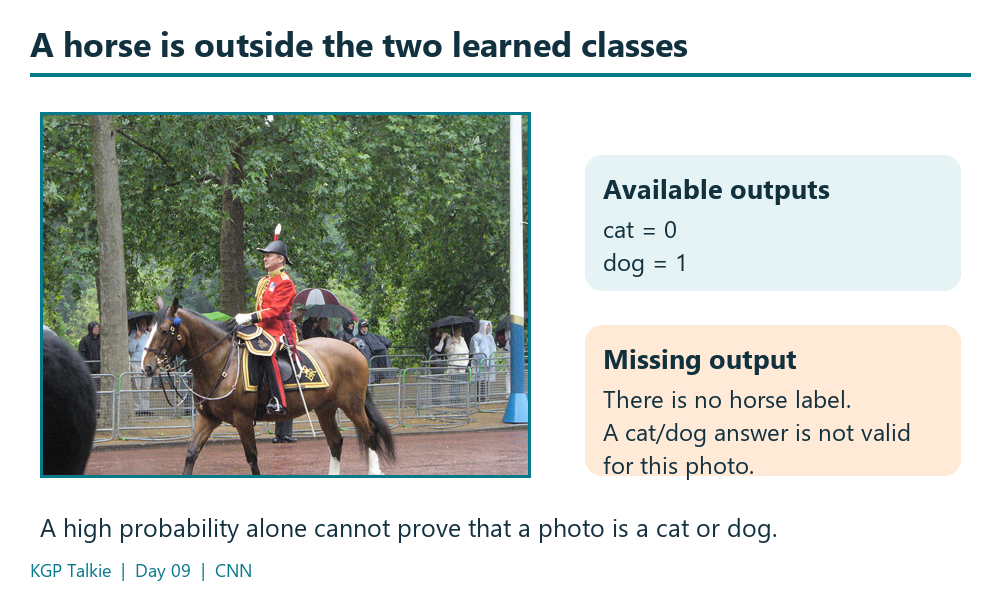

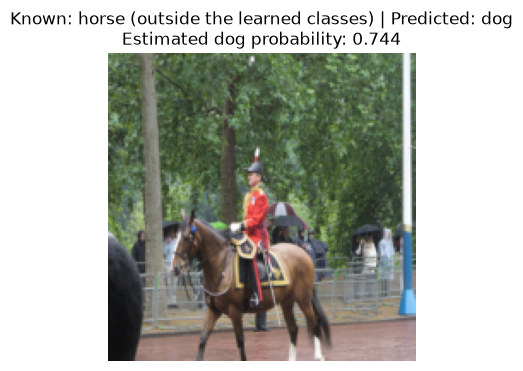

In [89]:
horse_check = predict_photo(horse_path, expected="horse (outside the learned classes)")  # Run it, but do not accept its forced cat/dog answer.

In [90]:
print("This is a horse. The binary output has no horse class, so its cat/dog label is not valid for this input.")

This is a horse. The binary output has no horse class, so its cat/dog label is not valid for this input.


## 15. Try your own cat or dog photo

Change the path below to an image file on your computer, then run it. For a photo without a known label, use `expected="not checked"`. View the image as well as the answer. The model can make mistakes.

In [91]:
my_photo_path = new_dog_path  # Replace with Path("your-photo.jpg") to test your own file.

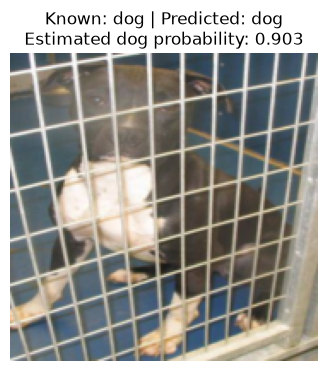

In [92]:
my_result = predict_photo(my_photo_path, expected="dog")  # Change expected too when you choose another photo.